# 01 — Análise exploratória das avaliações (F1)

Objetivo: medir a base de avaliações da Olist antes de montar a base de conhecimento do RAG, e registrar com números cada decisão de preparação (seleção, limpeza, ausentes, duplicatas, PII, organização dos documentos).

Pré-requisito: CSVs em `data/raw/` (ver `data/README.md`) e `python -m src.data.build_documents` já executado.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.data.load_olist import load_olist

IMG = ROOT / "docs" / "imagens"
t = load_olist(ROOT / "data" / "raw")
raw = t["reviews"]
reviews = pd.read_parquet(ROOT / "data" / "processed" / "reviews.parquet")
docs = pd.read_parquet(ROOT / "data" / "processed" / "documents.parquet")
stats = json.loads((ROOT / "data" / "processed" / "build_stats.json").read_text())
print(f"{len(raw):,} avaliações brutas | {len(reviews):,} únicas | {len(docs):,} documentos indexáveis")

99,224 avaliações brutas | 98,410 únicas | 42,121 documentos indexáveis


## 1. Valores ausentes: quem comenta

A maior parte dos clientes dá só a nota. Isso define o tamanho real da base de conhecimento e um viés que precisa ser declarado.

In [2]:
ausentes = pd.DataFrame({
    "sem título": [raw.review_comment_title.isna().mean()],
    "sem mensagem": [raw.review_comment_message.isna().mean()],
    "sem título e sem mensagem": [(raw.review_comment_title.isna() & raw.review_comment_message.isna()).mean()],
}).T.rename(columns={0: "% das avaliações"})
(ausentes * 100).round(1)

,% das avaliações
sem título,88.3
sem mensagem,58.7
sem título e sem mensagem,57.0


In [3]:
funil = pd.Series({
    "avaliações brutas": stats["avaliacoes_brutas"],
    "únicas (review_id)": stats["avaliacoes_unicas"],
    "com algum texto": stats["com_texto"],
    "texto informativo (documentos)": stats["documentos"],
}, name="quantidade")
funil.to_frame()

,quantidade
avaliações brutas,99224
únicas (review_id),98410
com algum texto,42370
texto informativo (documentos),42121


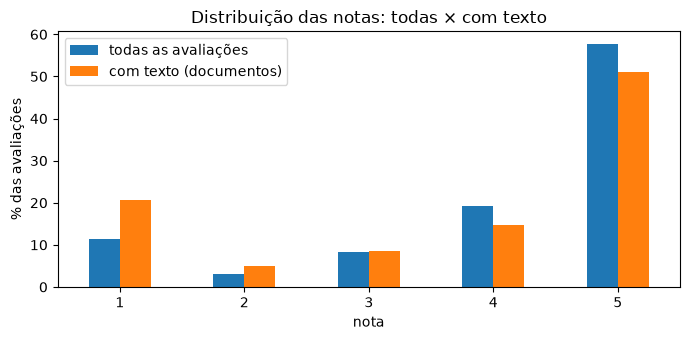

,todas as avaliações,com texto (documentos)
review_score,,
1,11.5,20.7
2,3.2,5.1
3,8.2,8.5
4,19.3,14.7
5,57.8,51.0


In [4]:
notas = pd.DataFrame({
    "todas as avaliações": reviews.review_score.value_counts(normalize=True),
    "com texto (documentos)": docs.review_score.value_counts(normalize=True),
}).sort_index() * 100
ax = notas.plot.bar(figsize=(7, 3.5), rot=0)
ax.set_xlabel("nota"); ax.set_ylabel("% das avaliações"); ax.set_title("Distribuição das notas: todas × com texto")
plt.tight_layout(); plt.savefig(IMG / "eda_notas_com_sem_texto.png", dpi=120); plt.show()
notas.round(1)

**Leitura:** quem escreve comentário tende a ser mais o cliente insatisfeito (a nota 1 pesa mais nos documentos do que no total). A base de conhecimento representa **quem comentou**, não todos os clientes. Por isso as perguntas agregadas contam sobre `reviews.parquet` (todas as avaliações) quando a pergunta é sobre notas, e sobre os documentos quando é sobre o conteúdo do texto. Isso é uma associação descritiva, não uma relação causal.

**Decisão:** avaliações sem título e sem mensagem ficam **fora do índice vetorial**, mas **dentro de `reviews.parquet`** para contagens. Só título ou só mensagem: usa o que existe.

## 2. Comprimento dos textos: por que não há chunking

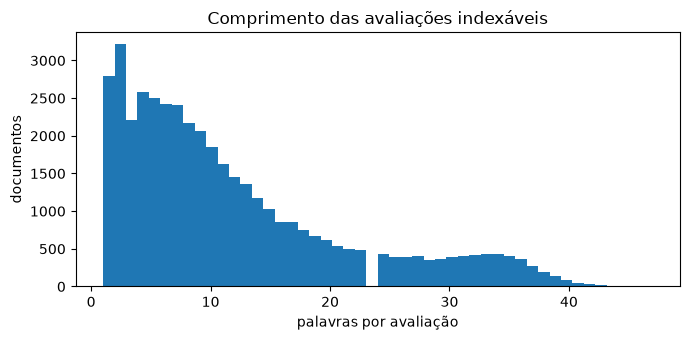

count    42121.0
mean        11.8
std          9.7
min          1.0
50%          9.0
90%         28.0
99%         38.0
max         47.0
Name: n_palavras, dtype: float64

In [5]:
ax = docs.n_palavras.plot.hist(bins=48, figsize=(7, 3.5))
ax.set_xlabel("palavras por avaliação"); ax.set_ylabel("documentos"); ax.set_title("Comprimento das avaliações indexáveis")
plt.tight_layout(); plt.savefig(IMG / "eda_comprimento.png", dpi=120); plt.show()
docs.n_palavras.describe(percentiles=[.5, .9, .99]).round(1)

**Decisão:** **1 avaliação = 1 documento, sem chunking.** O p99 fica abaixo de 40 palavras e o máximo perto de 50: toda avaliação cabe com folga num único embedding. Quebrar em pedaços só separaria a reclamação da sua causa ("chegou quebrado" / "embalagem ruim") e faria a citação apontar para um fragmento. A unidade semântica coincide com a unidade de evidência (`review_id`).

## 3. Duplicatas e cardinalidade dos joins

In [6]:
pd.Series({
    "review_id repetido em mais de um pedido": stats["review_id_em_varios_pedidos"],
    "pedidos com mais de uma avaliação": stats["pedidos_com_varias_avaliacoes"],
    "textos idênticos (documentos)": int(docs.texto_normalizado.str.lower().duplicated().sum()),
}, name="quantidade").to_frame()

,quantidade
review_id repetido em mais de um pedido,789
pedidos com mais de uma avaliação,547
textos idênticos (documentos),6023


In [7]:
docs.texto_normalizado.str.lower().value_counts().head(10).to_frame("documentos com esse texto")

,documentos com esse texto
texto_normalizado,
muito bom,461
bom,377
recomendo,343
ótimo,266
otimo,235
excelente,204
super recomendo,133
ok,122
boa,113


**Decisões:**
- `review_id` em vários pedidos → **1 documento**, `order_ids` concatenados e metadados do pedido mais recente (`multi_pedido=True`).
- Pedido com várias avaliações → **mantém todas** (são avaliações distintas).
- Textos idênticos ("muito bom", "recomendo") → **mantidos**: são clientes diferentes e contam para a frequência. A deduplicação acontece **na recuperação**, para o top-k não lotar de cópias.

## 4. Idioma

In [8]:
from langdetect import DetectorFactory, detect
DetectorFactory.seed = 0
amostra = docs[docs.n_palavras >= 4].sample(2000, random_state=42)
def idioma(t):
    try:
        return detect(t)
    except Exception:
        return "indefinido"
idiomas = amostra.texto_normalizado.map(idioma).value_counts(normalize=True).mul(100).round(1)
idiomas.head(8).to_frame("% da amostra (n=2000, textos com 4+ palavras)")

,"% da amostra (n=2000, textos com 4+ palavras)"
texto_normalizado,
pt,95.6
it,1.9
es,1.5
de,0.2
en,0.2
sk,0.1
ca,0.1
fr,0.0


**Decisão:** a base é praticamente toda em português. Os ~4% classificados como outro idioma são, nos casos conferidos à mão, textos curtos em português mal detectados (ex.: "Entrega dentro do prazo." saiu como italiano). Ficam todos, e o modelo de embedding é multilíngue de qualquer forma.

## 5. Dados pessoais (LGPD)

In [9]:
pd.Series(stats["pii_mascarada"], name="ocorrências mascaradas").to_frame()

,ocorrências mascaradas
[CPF],1
[TELEFONE],3


**Decisão:** telefones, CPF, e-mail e CEP são trocados por marcadores (`[TELEFONE]`, `[CPF]`...) **antes** de indexar, então não entram no índice, no contexto do LLM nem nas respostas. A base pública quase não tem PII, mas a regra protege contra o caso real.

## 6. Textos não informativos

In [10]:
nao_info = reviews[reviews.tem_texto & ~reviews.indexavel]
print(f"{len(nao_info)} avaliações com texto, mas sem conteúdo útil")
nao_info.texto_original.value_counts().head(10).to_frame("ocorrências")

249 avaliações com texto, mas sem conteúdo útil


,ocorrências
texto_original,
10,54
.,42
*****,12
9,10
...,9
8,8
5,8
. .,8
10. 10,6


**Decisão:** textos só com números, pontuação ou com menos de 2 caracteres (ex.: "10", "...", "A") ficam fora do índice. Um "10" é uma nota escrita, e a nota já está no metadado.

## 7. Metadados para o desafio opcional

In [11]:
entregues = docs[docs.entregue]
atraso = entregues.groupby("entregue_com_atraso").review_score.agg(["count", "mean"]).round(2)
atraso.index = atraso.index.map({False: "no prazo", True: "com atraso"})
atraso.rename(columns={"count": "documentos", "mean": "nota média"})

,documentos,nota média
entregue_com_atraso,,
no prazo,36433,4.00
com atraso,3810,1.94


In [12]:
docs.categoria_pt.value_counts().head(10).to_frame("documentos")

,documentos
categoria_pt,
cama_mesa_banho,4310
beleza_saude,3512
esporte_lazer,3015
informatica_acessorios,2781
moveis_decoracao,2579
relogios_presentes,2577
utilidades_domesticas,2459
telefonia,1880
automotivo,1753


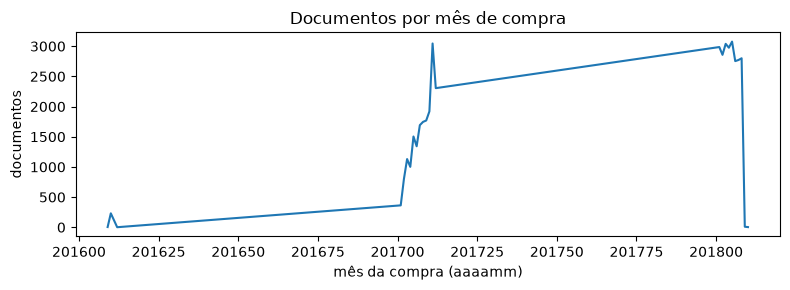

In [13]:
por_mes = docs.groupby("ano_mes_compra").size()
ax = por_mes.plot(figsize=(8, 3))
ax.set_xlabel("mês da compra (aaaamm)"); ax.set_ylabel("documentos"); ax.set_title("Documentos por mês de compra")
plt.tight_layout(); plt.show()

**Leitura:** avaliações de pedidos entregues com atraso têm nota média bem menor do que as entregues no prazo. É uma **associação**, não prova que o atraso causa a nota baixa, mas justifica `entregue_com_atraso` e `dias_atraso` como filtros: perguntas como "o que reclamam nas entregas atrasadas?" passam a recuperar só o recorte certo.

## Resumo das decisões (vai para o README, seção 3)

| Etapa | Decisão |
|---|---|
| Seleção | 6 tabelas: reviews (texto), orders, items, products, tradução de categoria, customers |
| Ausentes | Sem texto: fora do índice, dentro das contagens. Entrega nula: `entregue=False`, sem imputar. Categoria nula: `sem_categoria` |
| Limpeza | `texto_original` para citar; `texto_normalizado` com Unicode NFC, pontuação separada e abreviações expandidas; sem stemming, sem stop words, mantendo acentos e o "não" |
| Duplicatas | 1 documento por `review_id` (pedido mais recente); avaliações do mesmo pedido mantidas; textos idênticos mantidos |
| PII | Mascarada antes de indexar |
| Documentos | 1 avaliação = 1 documento, sem chunking |